<a href="https://colab.research.google.com/github/OjedaRocio/TP-Grupal-Laboratorio-2C-2026/blob/cambios.Rocio/TP_Grupal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Método Cuantitativos. FCE UBA-2C 2026


---


# TP-Grupal

**Integrantes**:

* *Ojeda Rocío, 921426*
* Zurita Fernandez Valentina, 921469
* *Uriarte Martinez Hilda Anabel, 921802*
*  *Aliaga Campos Tania Andrea, 921715*

**Repositorio:**
TP-Grupal-Laboratorio-2C-2026 ; **Dataset:** track_data_final.csv ; **Fuente:** https://www.kaggle.com/datasets/wardabilal/spotify-global-music-dataset-20092025?resource=download



---

**¿Es verdad que las canciones Globales se volvieron más cortas a lo largo del tiempo?**



In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 🤖 Declaración de Uso de IA en este Paso
*Con el fin de mantener la transparencia e integridad académica del proyecto, se detalla el uso de herramientas de Inteligencia Artificial para el desarrollo de esta sección:*

* **Herramienta utilizada**: Colab AI / Assistant (basado en Gemini).
* **Propósito**:  Diseño de un bloque de carga colaborativo dinámico entre integrantes.
* **Prompts:** *¿Qué pasa con la ruta del archivo si compartimos el notebook en GitHub con otra compañera?*

In [111]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos las rutas posibles para cada integrante del equipo o entorno
RUTA_LOCAL_COLAB = '/content/track_data_final.csv'
RUTA_DRIVE_ROCIO = '/content/drive/MyDrive/track_data_final.csv'
#ACA DEBEN DE CAMBIAR EL LINK DIRECTO A SU DRIVE, DESDE ARCHIVOS ABREN DRIVE BUSCAN EL DATA Y EN LOS TRES PUNTOS COPIAR RUTA DE ACCESO.
RUTA_DRIVE_VALENTINA = '/content/drive/MyDrive/dataset_colab/archivo.csv'
RUTA_DRIVE_HILDA = '/content/drive/MyDrive/DatosTP/track_data_final.csv'
RUTA_DRIVE_TANIA = '/content/drive/MyDrive/Compartido/track_data_final.csv'

# El código intenta elegir automáticamente la ruta que esté disponible en el entorno actual
if os.path.exists(RUTA_LOCAL_COLAB):
    ruta_activa = RUTA_LOCAL_COLAB
    print("Cargando archivo desde el almacenamiento local de Colab.")
elif os.path.exists(RUTA_DRIVE_ROCIO):
    ruta_activa = RUTA_DRIVE_ROCIO
    print("Cargando archivo desde el Drive de Rocío.")
elif os.path.exists(RUTA_DRIVE_VALENTINA):
    ruta_activa = RUTA_DRIVE_VALENTINA
    print("Cargando archivo desde el Drive de tu Valentina.")
elif os.path.exists(RUTA_DRIVE_HILDA):
    ruta_activa = RUTA_DRIVE_HILDA
    print("Cargando archivo desde el Drive de tu Hilda.")
elif os.path.exists(RUTA_DRIVE_TANIA):
    ruta_activa = RUTA_DRIVE_TANIA
    print("Cargando archivo desde el Drive de tu Tania.")
else:
    # Ruta de respaldo por si acaso
    ruta_activa = RUTA_LOCAL_COLAB
    print("No se detectó el archivo en las rutas configuradas. Usando ruta por defecto local.")

# Cargamos el DataFrame final utilizando la ruta seleccionada automáticamente
df_spotify = pd.read_csv(ruta_activa)

Cargando archivo desde el Drive de Rocío.


#Paso 1: Exploracion inicial de datos


---


##Antes de realizar el análisis profundo, procedimos a cargar los datos de Spotify para evaluar las columnas disponibles, identificar la cantidad total de canciones que contiene, detectar posibles datos nulos y unificar criterios en los tipos de datos.




In [112]:
#Visualizamos todo el data que tenemos.
df_spotify

,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album
3,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album
4,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8773,58VTP6KnZs12PcAj5rMJ4W,the fruits,1,65,209698,False,Paris Paloma,66.0,786890.0,[],48ssTnnFOCIP17sRaFNqu1,the fruits,2022-04-29,1,single
8774,2dRfUOeTVpr4V4PmmqGkpm,Dark World Theme (The Legend of Zelda),4,2,113143,False,Zelda,8.0,3263.0,[],0JJAfVZtn3EvZnXSQrpLSh,The Legend of Zelda,2023-08-19,7,album
8775,37F0uwRSrdzkBiuj0D5UHI,Reminder,4,81,218880,True,The Weeknd,94.0,113039308.0,[],2ODvWsOgouMbaA5xf0RkJe,Starboy,2016-11-25,18,album
8776,42qNWdLKCI41S4uzfamhFM,Duvet,1,84,203600,False,bôa,68.0,1188508.0,[],7sGYAV0xv7ZfAMzIpMl8m1,Twilight,2001-03-21,14,album


In [113]:
#visualizamos los primeros 10 datos
df_spotify.head(10)

,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
0,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation
1,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single
2,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album
3,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album
4,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album
5,7H0ya83CMmgFcOhw0UB6ow,Space Song,3,77,320466,False,Beach House,72.0,2803036.0,['dream pop'],194CqC2Zi0kUFEPWedb3qr,Depression Cherry,2015-08-28,9,album
6,41zXlQxzTi6cGAjpOXyLYH,idontwannabeyouanymore,2,78,203569,False,Billie Eilish,90.0,118692183.0,[],7fRrTyKvE4Skh93v97gtcU,dont smile at me,2017-12-22,9,single
7,13jRFAGT8qd6aBwtJySlUm,Allein Allein - BENNETT Remix,1,52,145977,False,Alok,76.0,11247155.0,"['brazilian bass', 'electronic', 'slap house',...",1WKoDELzbFRR6UWNGh50LO,Allein Allein (feat. FREY) [BENNETT Remix],2024-09-27,2,single
8,0N5zjRnf8AreOm95iSBXF4,Even My Dad Does Sometimes,15,50,228533,False,Ed Sheeran,88.0,122773292.0,['soft pop'],1xn54DMo2qIqBuMqHtUsFd,x (Deluxe Edition),2014-06-21,16,album
9,0qUcpOOna3kkrwfqky85e1,Eyes Blue Like The Atlantic (feat. Subvrbs),1,63,154599,False,Sista Prod,48.0,68226.0,[],5UYjxc4HIYeesKS0WJlhEI,Eyes Blue Like The Atlantic (feat. Subvrbs),2020-07-20,1,single


In [114]:
#visualizamos los ultimos 10 datos.
df_spotify.tail(10)

,track_id,track_name,track_number,track_popularity,track_duration_ms,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type
8768,2z71jdeVcC782NgsYZ6N8q,Paranoid (2012 Remaster),2,66,166693,False,Black Sabbath,75.0,9781962.0,"['metal', 'heavy metal', 'rock', 'stoner rock'...",7LGVdC9fFwgWYaIrZwsSv6,Paranoid,1970-09-18,8,album
8769,4y4spB9m0Q6026KfkAvy9Q,Lonely (with benny blanco),1,66,149297,True,Justin Bieber,91.0,85050158.0,[],3P5WIUJO0Ots1lQx09TOxk,Lonely (with benny blanco),2020-10-16,1,single
8770,6GFrELGVKBXRcrTNkwjSfF,Body And Mind,3,54,186672,False,girl in red,73.0,8771418.0,['bedroom pop'],69p42ovQdwmYPLUsAQpeNn,if i could make it go quiet,2021-04-30,11,album
8771,1gtflD7JVxpozNitZJp6xu,The Legend of Korra End Credits,25,34,30706,False,Jeremy Zuckerman,44.0,23565.0,[],2LOLFpqUHrlQPAiqzLVJBN,The Legend of Korra: Original Music From Book One,2013-07-16,26,album
8772,2d8JP84HNLKhmd6IYOoupQ,Trap Queen,1,77,222093,True,Fetty Wap,70.0,5124117.0,[],2gKQvajkEEaDtkqJ8FJ4uw,Fetty Wap (Deluxe),2015-09-25,20,album
8773,58VTP6KnZs12PcAj5rMJ4W,the fruits,1,65,209698,False,Paris Paloma,66.0,786890.0,[],48ssTnnFOCIP17sRaFNqu1,the fruits,2022-04-29,1,single
8774,2dRfUOeTVpr4V4PmmqGkpm,Dark World Theme (The Legend of Zelda),4,2,113143,False,Zelda,8.0,3263.0,[],0JJAfVZtn3EvZnXSQrpLSh,The Legend of Zelda,2023-08-19,7,album
8775,37F0uwRSrdzkBiuj0D5UHI,Reminder,4,81,218880,True,The Weeknd,94.0,113039308.0,[],2ODvWsOgouMbaA5xf0RkJe,Starboy,2016-11-25,18,album
8776,42qNWdLKCI41S4uzfamhFM,Duvet,1,84,203600,False,bôa,68.0,1188508.0,[],7sGYAV0xv7ZfAMzIpMl8m1,Twilight,2001-03-21,14,album
8777,7KZJnMtwu2s80jO5Frthap,So Much Better,4,33,261385,True,Eminem,88.0,104584370.0,"['rap', 'hip hop']",3vOgbDjgsZBAPwV2M3bNOj,The Marshall Mathers LP2,2013-11-05,16,album


In [115]:
#Comenzamos visualizando las columnas y filas del data
print("---Columnas, Filas & Tipos de datos.---")
print("")

print("Filas y Columnas:", df_spotify.shape)
print("")

df_spotify.info()


---Columnas, Filas & Tipos de datos.---

Filas y Columnas: (8778, 15)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8778 entries, 0 to 8777
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8778 non-null   object 
 1   track_name          8776 non-null   object 
 2   track_number        8778 non-null   int64  
 3   track_popularity    8778 non-null   int64  
 4   track_duration_ms   8778 non-null   int64  
 5   explicit            8778 non-null   bool   
 6   artist_name         8774 non-null   object 
 7   artist_popularity   8774 non-null   float64
 8   artist_followers    8774 non-null   float64
 9   artist_genres       8774 non-null   object 
 10  album_id            8778 non-null   object 
 11  album_name          8776 non-null   object 
 12  album_release_date  8778 non-null   object 
 13  album_total_tracks  8778 non-null   int64  
 14  album_type          8778 non-null

In [116]:
# Cuenta los valores nulos en cada columna
df_spotify.isnull().sum()

,0
track_id,0
track_name,2
track_number,0
track_popularity,0
track_duration_ms,0
explicit,0
artist_name,4
artist_popularity,4
artist_followers,4
artist_genres,4


# **Limpieza:**
aseguramos que las columnas que necesitamos (**artist_name** y **track_name**) queden sin un solo valor nulo antes de agrupar o graficar ya que nos aportaran informacion importante

In [117]:
# 1. Eliminar filas donde falte el Nombre de la Canción o el Nombre del Artista
df_spotify = df_spotify.dropna(subset=["track_name", "artist_name"]).reset_index(drop=True)

# 2. Verificar que esas dos columnas clave hayan quedado en 0 nulos
print("--- Verificación de Nulos en Columnas Clave ---")
print("Nulos en 'track_name':", df_spotify["track_name"].isnull().sum())
print("Nulos en 'artist_name':", df_spotify["artist_name"].isnull().sum())

# 3. Ver cuántas filas quedaron en total tras el descarte
print("\nCantidad total de filas procesadas:", len(df_spotify))

--- Verificación de Nulos en Columnas Clave ---
Nulos en 'track_name': 0
Nulos en 'artist_name': 0

Cantidad total de filas procesadas: 8772


# **Hallazgos:**
La columna **"album_release_date"** se encuentra como cadena de *texto*, necesitamos modificarla como **INT** para poder trabajar evoluciones temporales. Verificamos la forma de las fechas en el dataset original y corroboramos si existen registros con formatos diferentes a AAAA-MM-DD **priorizando el dato del AÑO (AAAA).**
Asumir que todas las entradas tienen día y mes puede generar la pérdida involuntaria de datos.

Se **analiza** la distribución de **la longitud** de las cadenas de texto para encontrar inconsistencias de origen antes de estructurar la columna definitiva del Año de lanzamiento.

In [118]:
# Contar cuántos caracteres tiene el texto de cada celda
# - 10 caracteres -> "AAAA-MM-DD" (Año-Mes-Día)
# - 7 caracteres  -> "AAAA-MM" (Año-Mes)
# - 4 caracteres  -> "AAAA" (Solo año)
conteo_formatos = df_spotify["album_release_date"].astype(str).str.len().value_counts()

print("--- Distribución de longitud del texto en 'album_release_date' ---")
print(conteo_formatos)

--- Distribución de longitud del texto en 'album_release_date' ---
album_release_date
10    8573
4      196
7        3
Name: count, dtype: int64


# **Hallazgos:**
Notamos que tenemos datos que solo contienen **año** y no los queremos *perder* en un paso intermedio de limpieza.

**Solucion:** extraer los **primeros 4 dígitos numéricos** consecutivos que representan el año, sin importar si la cadena contiene solo el año o la fecha completa.

In [119]:
# Filtrar y mostrar las filas que tienen solo 4 caracteres en la fecha
solo_anios = df_spotify[df_spotify["album_release_date"].astype(str).str.len() == 4]

# Mostrar las primeras 5 filas para comprobar su contenido
display(solo_anios[["track_name", "artist_name", "album_release_date"]].head())

,track_name,artist_name,album_release_date
27,Did It Again,Shakira,2009
49,9 to 5,Dolly Parton,1980
67,My Bubble Gum,Rasheeda,2007
87,Run,Leona Lewis,2007
92,Popular,The Veronicas,2005



# **Hallazgos:**
 Columna **"track_duration_ms"** numero entero en *milisegundos*, queremos pasarlos a **minutos** para que sea mas facil leer y utilizar los datos a la hora de compararlos.

### 🤖 Declaración de Uso de IA en este Paso


* **Herramienta utilizada**: chat_gpt proyect
* **Propósito**: transformar fechas y minutos
* **Prompts:** *Como analista de datos senior de la indrustria musical, armate un codigo para poder extraer solo el año en formato entero (int) de la columna de fechas del dataset track_data_final, rescatando los años de 4 digitos. Y ademas un codigo para poder visualizar esto junto con el cambio de minutos de reproduccion.*

In [120]:
# 1. Insertar el ID único numérico
df_spotify.insert(0, "ID canción", range(1, len(df_spotify) + 1))

# 2. Convertir la duración de milisegundos a minutos
df_spotify["duracion_minutos"] = (
    pd.to_numeric(df_spotify["track_duration_ms"], errors="coerce") / 60000
).round(2)

# 3. EXTRAER SOLO EL AÑO COMO ENTERO (INT):
# Extrae los 4 dígitos (AAAA) de la columna de texto original y los transforma a número entero (int)
df_spotify["album_release_year"] = (
    df_spotify["album_release_date"]
    .astype(str)
    .str.extract(r'(\d{4})')[0]
    .astype(int)
)

# 4. Cambiar los nombres de las columnas para facilitar su lectura
df = df_spotify.rename(columns={
    "track_id": "ID Spotify",
    "track_name": "Nombre de la canción",
    "track_number": "Número de pista",
    "track_popularity": "Popularidad de la canción",
    "track_duration_ms": "Duración original (ms)",
    "explicit": "Contenido explícito",
    "artist_name": "Nombre del artista",
    "artist_popularity": "Popularidad del artista",
    "artist_followers": "Seguidores del artista",
    "artist_genres": "Géneros musicales",
    "album_id": "ID del álbum",
    "album_name": "Nombre del álbum",
    "album_release_date": "Fecha de lanzamiento original",
    "album_release_year": "Año de lanzamiento",
    "album_total_tracks": "Cantidad de canciones del álbum",
    "album_type": "Tipo de álbum",
    "duracion_minutos": "Duración (minutos)"
})

# Mostrar algunas filas para comprobar el resultado
display(df.head())

# Guardar el dataset con los cambios
df.to_csv("track_data_final_legible.csv", index=False, encoding="utf-8-sig")

,ID canción,ID Spotify,Nombre de la canción,Número de pista,Popularidad de la canción,Duración original (ms),Contenido explícito,Nombre del artista,Popularidad del artista,Seguidores del artista,Géneros musicales,ID del álbum,Nombre del álbum,Fecha de lanzamiento original,Cantidad de canciones del álbum,Tipo de álbum,Duración (minutos),Año de lanzamiento
0,1,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation,3.55,2009
1,2,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single,2.65,2023
2,3,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album,3.76,2021
3,4,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album,2.64,2021
4,5,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album,4.45,2010


In [121]:
# 1. Comprobar la cantidad de valores nulos en la nueva columna
nulos_año = df["Año de lanzamiento"].isnull().sum()
print("Cantidad de nulos en 'Año de lanzamiento':", nulos_año)

# 2. Verificar el tipo de dato (debe ser int64)
print("Tipo de dato de la columna:", df["Año de lanzamiento"].dtype)

# 3. Ver un resumen del rango de años rescatados
print("Año mínimo:", df["Año de lanzamiento"].min())
print("Año máximo:", df["Año de lanzamiento"].max())

Cantidad de nulos en 'Año de lanzamiento': 0
Tipo de dato de la columna: int64
Año mínimo: 1952
Año máximo: 2025


# **Hallazgos**:
Al buscar **Año minimo** encontramos un valor **atipico** (**1952**), el cual debemos comprobar para que *no distorcione* la escala cronológica de los futuros gráficos evolutivos.
Verificar exactamente cuántas canciones hay en cada año y corroborar este posible **hueco temporal**

In [122]:
# Contar la cantidad de canciones por año y ordenarlos cronológicamente
conteo_por_año = df["Año de lanzamiento"].value_counts().sort_index()

print("--- DISTRIBUCIÓN DE CANCIONES POR AÑO ---")
print(conteo_por_año)

--- DISTRIBUCIÓN DE CANCIONES POR AÑO ---
Año de lanzamiento
1952      1
1958      1
1959      5
1960      1
1962      5
       ... 
2021    448
2022    475
2023    525
2024    658
2025    768
Name: count, Length: 68, dtype: int64


# **Hallazgos:**
Al inspeccionar la distribución de canciones por año de lanzamiento, se detectó la presencia de años aislados en décadas pasadas con un dato muestral insignificante ($n < 10$, como 1952 o 1958 con solo $1$ observación).
Se definió un **umbral** de representatividad de al menos $100$ canciones por año ($n \ge 100$). Este filtro descarta el ruido estadístico de la "cola larga" sin afectar el núcleo del dataset (2009–2025), garantizando que cada punto en la serie temporal responda a un volumen estadísticamente sólido.   

In [123]:
# 1. Agrupar por año y calcular tamaño muestral (n), desviación estándar (s) y Error Estándar (SE)
estadisticas_anios = df.groupby("Año de lanzamiento")["Duración (minutos)"].agg(
    n="count",
    promedio="mean",
    desviacion="std"
).reset_index()

# 2. Calcular el Error Estándar de la Media (SE = std / sqrt(n))
import numpy as np
estadisticas_anios["error_estandar"] = estadisticas_anios["desviacion"] / np.sqrt(estadisticas_anios["n"])

# 3. Mostrar comparativa entre años de baja densidad (n < 100) y alta densidad (n >= 100)
print("--- COMPARATIVA DE ERROR ESTÁNDAR SEGÚN TAMAÑO MUESTRAL ---")
print("\nAños con baja representatividad (n < 100):")
display(estadisticas_anios[estadisticas_anios["n"] < 100].head(5))

print("\nAños con alta representatividad (n >= 100):")
display(estadisticas_anios[estadisticas_anios["n"] >= 100].head(5))

--- COMPARATIVA DE ERROR ESTÁNDAR SEGÚN TAMAÑO MUESTRAL ---

Años con baja representatividad (n < 100):


,Año de lanzamiento,n,promedio,desviacion,error_estandar
0,1952,1,2.030,NaN,NaN
1,1958,1,2.740,NaN,NaN
2,1959,5,3.058,1.009242,0.451347
3,1960,1,2.270,NaN,NaN
4,1962,5,2.702,0.292609,0.130859



Años con alta representatividad (n >= 100):


,Año de lanzamiento,n,promedio,desviacion,error_estandar
45,2003,103,3.748058,1.023795,0.100878
49,2007,110,3.433455,1.032119,0.098409
50,2008,103,4.050388,1.263470,0.124493
51,2009,158,3.753354,1.054257,0.083872
52,2010,251,3.913785,0.984775,0.062158


Con un tamaño muestral de n ≥ 100 por año, el Error Estándar de la Media (SE) es del orden de 0,1 minutos o menos (unos 6 segundos). Es un margen chico frente a la caída que observamos más adelante (cerca de 50 segundos), por lo que las variaciones del gráfico reflejan tendencias y no simple azar.

In [124]:
# 1. Contar canciones por año
conteo_anios = df["Año de lanzamiento"].value_counts().sort_index()

# 2. Filtrar solo los años con 100 canciones o más
anios_representativos = conteo_anios[conteo_anios >= 100]

print("--- AÑOS CON 100 O MÁS CANCIONES ---")
print(anios_representativos)
print("\nPrimer año representativo en el dataset:", anios_representativos.index.min())

--- AÑOS CON 100 O MÁS CANCIONES ---
Año de lanzamiento
2003    103
2007    110
2008    103
2009    158
2010    251
2011    270
2012    335
2013    316
2014    352
2015    405
2016    388
2017    473
2018    534
2019    500
2020    494
2021    448
2022    475
2023    525
2024    658
2025    768
Name: count, dtype: int64

Primer año representativo en el dataset: 2003


In [125]:
# 1. Aplicar el filtro definitivo (>= 2003) sobre el mismo DataFrame
df = df[df["Año de lanzamiento"] >= 2003].copy()

# 2. Configurar Pandas para ver todas las columnas prolijas
pd.set_option('display.max_columns', None)

# 3. Mostrar el resumen del dataset filtrado
print("--- RESUMEN DEL DATASET LIMPIO Y FILTRADO ---")
print("Total de filas y columnas:", df.shape)
print("Cantidad de nulos en 'Año de lanzamiento':", df["Año de lanzamiento"].isnull().sum())
print("Rango de años representativo:", df["Año de lanzamiento"].min(), "-", df["Año de lanzamiento"].max())

# Visualizar las primeras 5 filas
display(df.head())

--- RESUMEN DEL DATASET LIMPIO Y FILTRADO ---
Total de filas y columnas: (7911, 18)
Cantidad de nulos en 'Año de lanzamiento': 0
Rango de años representativo: 2003 - 2025


,ID canción,ID Spotify,Nombre de la canción,Número de pista,Popularidad de la canción,Duración original (ms),Contenido explícito,Nombre del artista,Popularidad del artista,Seguidores del artista,Géneros musicales,ID del álbum,Nombre del álbum,Fecha de lanzamiento original,Cantidad de canciones del álbum,Tipo de álbum,Duración (minutos),Año de lanzamiento
0,1,6pymOcrCnMuCWdgGVTvUgP,3,57,61,213173,False,Britney Spears,80.0,17755451.0,['pop'],325wcm5wMnlfjmKZ8PXIIn,The Singles Collection,2009-11-09,58,compilation,3.55,2009
1,2,2lWc1iJlz2NVcStV5fbtPG,Clouds,1,67,158760,False,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,2023-01-13,1,single,2.65,2023
2,3,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),11,63,225328,False,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),2021-04-09,26,album,3.76,2021
3,4,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,2,72,158463,True,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,2021-07-30,16,album,2.64,2021
4,5,0GLfodYacy3BJE7AI3A8en,Man Down,7,57,267013,False,Rihanna,90.0,68997177.0,[],5QG3tjE5L9F6O2vCAPph38,Loud,2010-01-01,13,album,4.45,2010


# **Procedimiento:**
Nos queda por verificar que no hayan **datos duplicados**.

**Contexto:** Cada cancion en Spotify tiene un **ID** unico correspondiente, sin embargo en la industria
musical es habitual que los artistas publiquen el mismo tema en *diferentes formatos*.

Si evaluamos unicamente por el ID, estas versiones pasarian desapercibidas y generaria una **redundancia** que *sesgaria* los calculos de duracion en promedio anual.

**Solucion:** Se evalua la existencia de duplicados **eliminando las re-ediciones** para conservar únicamente la primera aparición registrada

In [126]:
# 1. Contar cuántos duplicados exactos hay por el ID único de Spotify
duplicados_id = df["ID Spotify"].duplicated().sum()

# 2. Contar cuántas canciones repetidas hay (mismo nombre de canción y mismo artista)
duplicados_cancion = df.duplicated(subset=["Nombre de la canción", "Nombre del artista"]).sum()

print("--- RESULTADO DE LA AUDITORÍA DE DUPLICADOS ---")
print("1. Registros duplicados por ID Spotify:", duplicados_id)
print("2. Canciones repetidas (Mismo Nombre + Mismo Artista):", duplicados_cancion)

--- RESULTADO DE LA AUDITORÍA DE DUPLICADOS ---
1. Registros duplicados por ID Spotify: 0
2. Canciones repetidas (Mismo Nombre + Mismo Artista): 812


### **Validación muestral de duplicados**

Antes de proceder con la eliminación automática de los 812 registros identificados, se realiza una **inspección visual de control** sobre una muestra de estos datos.

* **Objetivo del control:** Verificar que los registros duplicados en par `(Canción, Artista)` corresponden efectivamente a la misma obra musical (misma duración) publicada en diferentes álbumes o sencillos, y no a versiones alternativas (como versiones en vivo, *remixes* o re-grabaciones de distinta duración).

In [127]:
# Filtrar y mostrar las filas duplicadas agrupadas para inspeccionarlas
filas_duplicadas = df[df.duplicated(subset=["Nombre de la canción", "Nombre del artista"], keep=False)].sort_values(by=["Nombre del artista", "Nombre de la canción"])

print("\n--- EJEMPLOS DE CANCIONES REPETIDAS EN EL DATASET ---")
display(filas_duplicadas[["Nombre de la canción", "Nombre del artista", "Nombre del álbum", "Año de lanzamiento", "Duración (minutos)"]].head(12))


--- EJEMPLOS DE CANCIONES REPETIDAS EN EL DATASET ---


,Nombre de la canción,Nombre del artista,Nombre del álbum,Año de lanzamiento,Duración (minutos)
1449,Mood (feat. iann dior),24kGoldn,El Dorado,2021,2.34
7437,Mood (feat. iann dior),24kGoldn,Mood (feat. iann dior),2020,2.34
2905,Candy Shop,50 Cent,The Massacre,2005,3.49
4559,Candy Shop,50 Cent,The Massacre,2005,3.48
110,In Da Club,50 Cent,00s Middle School Dance,2019,3.22
2460,In Da Club,50 Cent,Get Rich Or Die Tryin',2003,3.22
3525,In Da Club,50 Cent,Get Rich Or Die Tryin',2003,3.22
702,Sail,AWOLNATION,Megalithic Symphony,2011,4.32
4731,Sail,AWOLNATION,Megalithic Symphony Deluxe,2011,4.32
4498,Aquamarine,Addison Rae,Aquamarine,2024,2.71


# **Hallazgos:**


*   Duración idéntica entre registros repetidos
*   Re-ediciones y relanzamientos en álbumes distintos

Conservar estas entradas duplicadas generaría una **sobre-representación** de ciertos temas en la muestra, distorsionando las *métricas de tendencia central*



In [128]:
# Ordenamos por año para quedarnos con el lanzamiento MÁS ANTIGUO de cada canción
df = (df.sort_values("Año de lanzamiento")
        .drop_duplicates(subset=["Nombre de la canción", "Nombre del artista"], keep="first")
        .reset_index(drop=True))



In [129]:
# Años con al menos 100 canciones DESPUÉS de eliminar duplicados
conteo = df.groupby("Año de lanzamiento").size()
print(conteo[conteo >= 100])

# Ventana continua de análisis
df = df[df["Año de lanzamiento"].between(2009, 2025)].copy()
print("Canciones en la ventana 2009-2025:", len(df))

Año de lanzamiento
2007    106
2009    141
2010    210
2011    234
2012    255
2013    278
2014    312
2015    354
2016    346
2017    421
2018    493
2019    471
2020    439
2021    382
2022    438
2023    488
2024    595
2025    726
dtype: int64
Canciones en la ventana 2009-2025: 6583


Queremos presentar las métricas de duración en un formato que refleje el **estandar de la industria musical** y la intuición del lector.

Agrupar los datos en años para poder sacar **promedio y mediana**.

La conversión a formato **sexagesimal** (MM:SS) permite comunicar las métricas en el formato real de *reproducción comercial*.


In [130]:
# 1. Contar canciones por año
conteo_anios = df.groupby("Año de lanzamiento").size()

# 2. Seleccionar años con al menos 100 canciones
anios_representativos = conteo_anios[conteo_anios >= 100].index

# 3. Filtrar el dataset
df_representativo = df[
    df["Año de lanzamiento"].isin(anios_representativos)
].copy()

# 4. Calcular las métricas anuales
resumen_anual = df_representativo.groupby("Año de lanzamiento")[
    "Duración (minutos)"
].agg(
    Canciones="count",
    Promedio_min="mean",
    Mediana_min="median"
).reset_index()

# 5. Convertir minutos decimales a MM:SS
def minutos_a_mmss(minutos_decimales):
    total_segundos = int(round(minutos_decimales * 60))
    minutos = total_segundos // 60
    segundos = total_segundos % 60
    return f"{minutos:02d}:{segundos:02d}"

resumen_anual["Promedio (MM:SS)"] = resumen_anual["Promedio_min"].apply(minutos_a_mmss)
resumen_anual["Mediana (MM:SS)"] = resumen_anual["Mediana_min"].apply(minutos_a_mmss)

# 6. Mostrar la tabla
display(
    resumen_anual[
        ["Año de lanzamiento", "Canciones", "Promedio (MM:SS)", "Mediana (MM:SS)"]
    ]
)

,Año de lanzamiento,Canciones,Promedio (MM:SS),Mediana (MM:SS)
0,2009,141,03:42,03:37
1,2010,210,03:57,03:51
2,2011,234,03:44,03:44
3,2012,255,03:53,03:49
4,2013,278,03:55,03:51
5,2014,312,03:42,03:44
6,2015,354,03:40,03:38
7,2016,346,03:36,03:36
8,2017,421,03:34,03:33
9,2018,493,03:25,03:24


### **Análisis interpretativo de la tendencia temporal (2009–2025)**

A partir de la tabla de agregación por año, respondemos a la pregunta inicial: **sí, las canciones se acortaron a lo largo del tiempo.**

* **Nivel alto (2009–2013):** la duración promedio se mantuvo entre 03:42 y 03:57, con un máximo de **03:57** en 2010.
* **Descenso (2013–2022):** desde 2013 (03:55) la duración baja prácticamente año a año hasta **03:06** en 2022, unos **49 segundos menos** (~21%). Hay un repunte puntual en 2021 (03:20).
* **Estabilización (2022–2025):** en los últimos años el promedio se mueve entre 03:06 y 03:04, es decir, la caída se frena.
* **Balance total:** entre el pico de 2010 y 2025 el promedio pasó de 03:57 a 03:04 (~53 segundos, ~22% menos).
* **Consistencia entre métricas:** el promedio y la mediana se mueven juntos en todo el período, lo que indica que la baja no depende de unos pocos temas extremos.


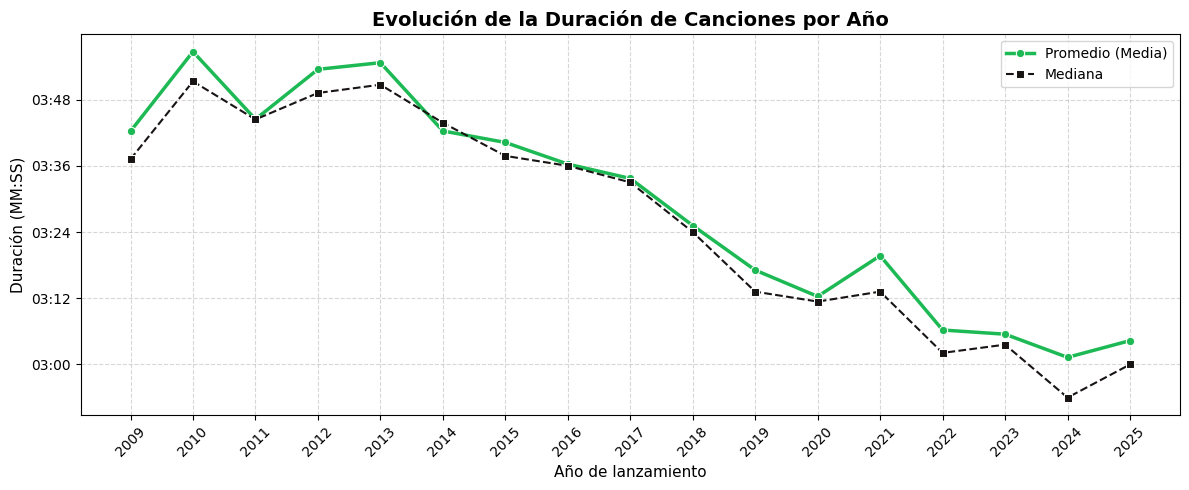

In [131]:
from matplotlib.ticker import FuncFormatter

# 1. Asegurar la muestra filtrada por representatividad (n >= 100)
df_representativo = df[
    df.groupby("Año de lanzamiento")["Año de lanzamiento"]
    .transform("count") >= 100
].copy()

# 2. Agrupar por todos los años
resumen_completo = df_representativo.groupby("Año de lanzamiento")[
    "Duración (minutos)"
].agg(
    Promedio="mean",
    Mediana="median",
    Canciones="count"
).reset_index()

# 3. Función para convertir minutos decimales a MM:SS
def formato_minutos_segundos(valor, posicion):
    minutos = int(valor)
    segundos = round((valor - minutos) * 60)

    if segundos == 60:
        minutos += 1
        segundos = 0

    return f"{minutos:02d}:{segundos:02d}"

# 4. Graficar la evolución temporal
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=resumen_completo,
    x="Año de lanzamiento",
    y="Promedio",
    marker="o",
    label="Promedio (Media)",
    color="#1DB954",
    linewidth=2.5
)

sns.lineplot(
    data=resumen_completo,
    x="Año de lanzamiento",
    y="Mediana",
    marker="s",
    label="Mediana",
    color="#191414",
    linestyle="--"
)

plt.title(
    "Evolución de la Duración de Canciones por Año",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Año de lanzamiento", fontsize=11)
plt.ylabel("Duración (MM:SS)", fontsize=11)

# Aplicar formato MM:SS al eje Y
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(formato_minutos_segundos)
)

plt.xticks(resumen_completo["Año de lanzamiento"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

# **Grafico:**
 Muestra que la media (**promedio**) y la **mediana** son casi *iguales*.

 El promedio y la mediana evolucionan de forma muy parecida, por lo que la baja de duración no depende de unos pocos temas extremos: se observa en el conjunto de la muestra.

 # 📊**Análisis Comparativo del Cambio en Duracion de canciones por períodos:**
 Con el propósito de analizar la estructura de la oferta y las tendencias del mercado musical, se procedió a categorizar la variable continua de **Duración (minutos)** en tres intervalos discretos:

 * **Cortas:** Menos de 3 minutos (< 3 min).
 * **Estándar:** Entre 3 y 4 minutos (3 a 4 min).
 * **Largas:** Más de 4 minutos ( > 4 min).

 Para observar la evolución real del mercado sin saturar la visualización con datos de cada año individual, se segmentó la muestra en tres grandes etapas de la industria musical:

 * Inicio del Streaming: **2009–2014**

 * Consolidacion de Plataformas: **2015–2019**

 * Explosion de formato corto, Reels y Viralidad: **2020–2025**


 🎯**Objetivo:**

 El proposito de esta visualizacion es evidenciar como las transformaciones en el metodo de consumo (el inicio de plataformas de Streming y el contenido corto) de la industria cambiaron las estrucutura de la oferta musical, permitiendo ver si hay una tendencia hacia la producción de canciones mas cortas.

/tmp/ipykernel_1297/3321436630.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Cortas' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[df['Duración (minutos)'] < 3.0, 'Categoria_Duracion'] = 'Cortas'
/tmp/ipykernel_1297/3321436630.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2009-2014' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[df['Año de lanzamiento'] < 2015, 'Periodo'] = '2009-2014'


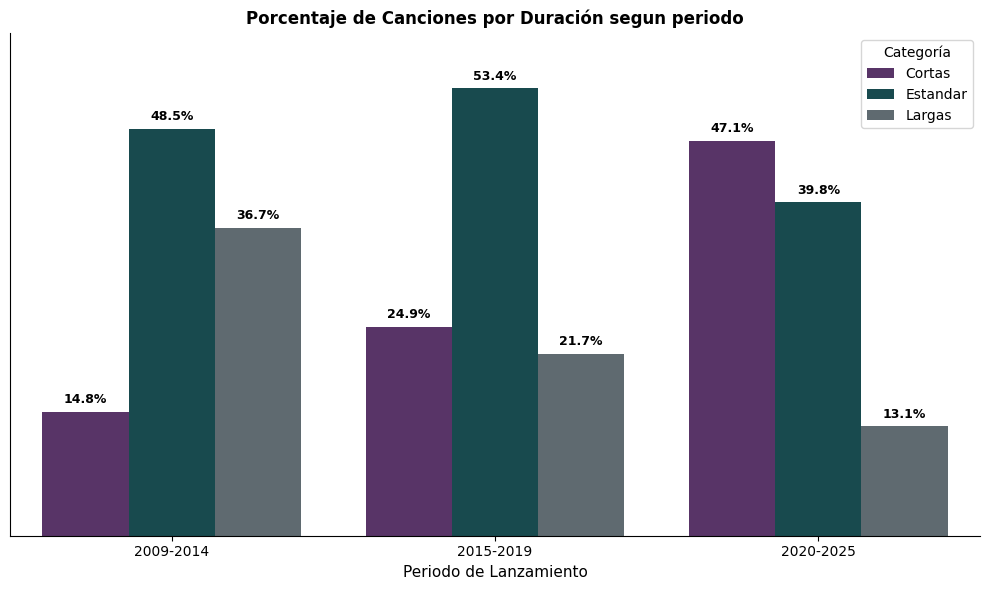

In [137]:
# Aseguramos que la columna sea de tipo texto para evitar conflictos con el tipo Categorical anterior
df['Categoria_Duracion'] = df['Duración (minutos)'].astype(float) # inicialización

# Categorizamos segun duración
df.loc[df['Duración (minutos)'] < 3.0, 'Categoria_Duracion'] = 'Cortas'
df.loc[(df['Duración (minutos)'] >= 3.0) & (df['Duración (minutos)'] < 4.0), 'Categoria_Duracion'] = 'Estandar'
df.loc[df['Duración (minutos)'] >= 4.0, 'Categoria_Duracion'] = 'Largas'

# Creamos los 3 Períodos Temporales
df['Periodo'] = np.nan
df.loc[df['Año de lanzamiento'] < 2015, 'Periodo'] = '2009-2014'
df.loc[(df['Año de lanzamiento'] >= 2015) & (df['Año de lanzamiento'] <= 2019), 'Periodo'] = '2015-2019'
df.loc[df['Año de lanzamiento'] >= 2020, 'Periodo'] = '2020-2025'

# Porcentaje (%) de categoria por periodo
df_pct = df.groupby('Periodo')['Categoria_Duracion'].value_counts(normalize=True).reset_index(name='Porcentaje')
df_pct['Porcentaje'] = df_pct['Porcentaje'] * 100

# Grafico de Barras
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_pct,
    x='Periodo',
    y='Porcentaje',
    hue='Categoria_Duracion',
    hue_order=['Cortas','Estandar','Largas'],
    palette=['#5B2C6F', '#0F5257', '#5C6B73']
)

# Para poner porcentajes sobre las barras
plt.ylim(0, 60)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=4, fontsize=9, fontweight='bold')

# Para ocultar eje Y
ax.get_yaxis().set_visible(False)
sns.despine(left=True)

plt.title("Porcentaje de Canciones por Duración segun periodo", fontsize=12, fontweight="bold")
plt.xlabel("Periodo de Lanzamiento", fontsize=11)
plt.legend(title="Categoría")
plt.grid(axis='y', linestyle="--", alpha=0.5)

sns.despine()
plt.tight_layout()
plt.savefig("grafico_porcentaje_duracion_por_periodo.png", dpi=300, bbox_inches="tight")
plt.show()

### 📓 Análisis:


El gráfico confirma el acortamiento. Las canciones **cortas** (< 3 min) pasaron de **14,8%** en 2009–2014 a **24,9%** en 2015–2019 y a **47,1%** en 2020–2025. En paralelo, las **largas** (> 4 min) cayeron de **36,7%** a **21,7%** y a **13,1%**. Es decir, en 2009–2014 una de cada seis canciones duraba menos de 3 minutos; en 2020–2025 es casi una de cada dos.

 # **Análisis de Relación entre Duración y Popularidad:**
 A partir del analisis anterior nos surgen las siguiente preguntas
 * ¿Existe una relación directa entre la brevedad de una cancion y su nivel de popularidad?
 * ¿Hacer canciones mas cortas amplifica la masividad de estas?

Para poder evaluar esta asociación hacemos uso de un grafico de dispercion junto con una linea de tendencia por MCO y el calculo de Coeficiente de Pearson

Coeficiente de Correlación de Pearson (r): 0.1076


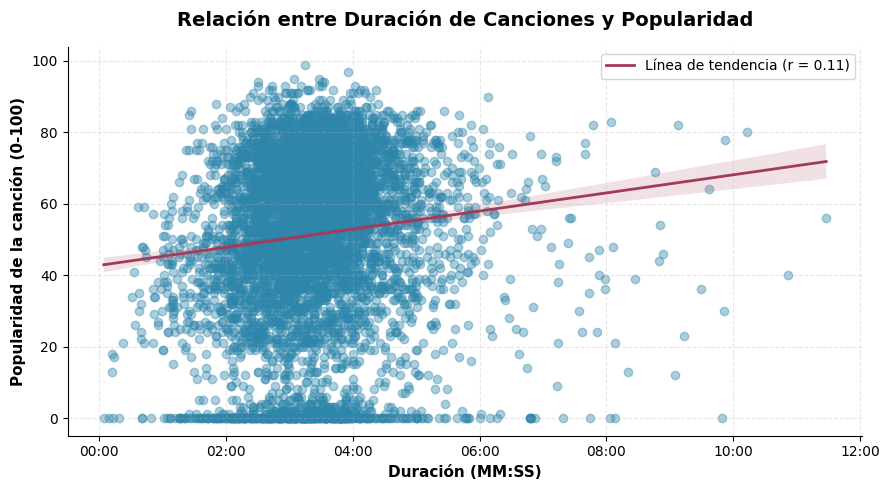

In [138]:
from matplotlib.ticker import FuncFormatter

# Calculamos coeficiente de correlación de Pearson entre ambas variables
correlacion = df['Duración (minutos)'].corr(df['Popularidad de la canción'])
print(f"Coeficiente de Correlación de Pearson (r): {correlacion:.4f}")

# Función para convertir minutos decimales a formato MM:SS en el eje X
def formato_minutos_segundos_eje(valor, posicion):
    minutos = int(valor)
    segundos = round((valor - minutos) * 60)
    if segundos == 60:
        minutos += 1
        segundos = 0
    return f"{minutos:02d}:{segundos:02d}"

# Figura de dispersión
plt.figure(figsize=(9, 5))

# Graficamos la nube de puntos con la línea de tendencia de Seaborn
sns.regplot(
    data=df,
    x='Duración (minutos)',
    y='Popularidad de la canción',
    scatter_kws={'alpha': 0.4, 'color': '#2E86AB'},
    # Apariencia de puntos
    line_kws={'color': '#A23B57', 'linewidth': 2, 'label': f'Línea de tendencia (r = {correlacion:.2f})'}
)

# Formato
plt.title("Relación entre Duración de Canciones y Popularidad",
           fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Duración (MM:SS)", fontsize=11, fontweight="bold")
plt.ylabel("Popularidad de la canción (0-100)", fontsize=11, fontweight="bold")

# Aplicar formato MM:SS al eje X
plt.gca().xaxis.set_major_formatter(FuncFormatter(formato_minutos_segundos_eje))

plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.3)
sns.despine()

plt.tight_layout()

plt.savefig("Relacion_entre_Duracion_de_canciones_y_Popularidad.png", dpi=300, bbox_inches="tight")
plt.show()

### 📓 Análisis:

Al examinar la visualizacion se pueden extraer las siguientes observaciones.
* Concentracion de oferta: Existe una gran concentracion de canciones entre los 2 y 4.5 minutos teniendo un amplio rango de popularidad que va desde temas con popularidad cercana a 0 a los más exitosos

* Se puede observar a la vez una cantidad de canciones que tienen una duracion mayor a 6 minutos que sostienen niveles de popularidad medio-alto. Demostrando que la duracion de una cancion no impide tener un buen rendimiento comercial.

* Analisis de la Regresion y Correlacion:  La linea de regresion presenta una leve pendiente positiva debido a temas cortos con popularidad nula que tiran la parte izquierda del grafico hacia abajo y la presencia de canciones de larga duracion con alta popularidad que elevan el extremo derecho. **Sin embargo** el coeficiente de Correlacion de Pearson es r = 0.1076 Esto podria decirnos que la relacion entre ambas variables es practicamente nula

#### **Identificacion de Sesgo:**
 Debido a la mezcla de canciones historicas que acumularon reproducciones a lo largo del tiempo con lanzamientos recientes moldeado por plataformas como TikTok, analizar los datos de manera global sin contemplar los años de lanzamiento conduce a una conclusion sesgada por el periodo estudiado


#Boxplot por categorias en periodo (2020-2025)
Para evaluar si verdaderamente existe un beneficio comercial en acortar canciones en la actualidad influenciado por el consumo de contenido, debemos realizar un analisis reflejando la submuestra del periodo reciente 2020-2025.

🎯**Objetivo**:

 Evaluar si la estrategia de a cortar temas realmente da un beneficio real de popularidad.

Resumen Estadístico de Popularidad por Categoría


,Categoria_Duracion,Canciones,Mediana,Q1,Q3
0,Cortas (< 3 min),1446,50.0,33.0,67.0
1,Estándar (3 - 4 min),1221,60.0,41.0,72.0
2,Largas (> 4 min),401,61.0,42.0,72.0


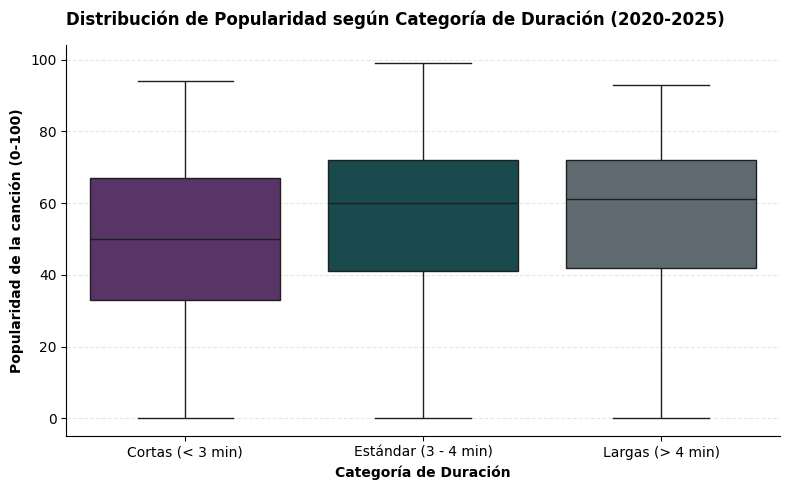

In [140]:
#Segmentamos la duración en categorías
df['Duración (minutos)'] = pd.to_numeric(df['Duración (minutos)'], errors='coerce')

limites = [0, 3.0, 4.0, np.inf]
...
df['Categoria_Duracion'] = pd.cut(df['Duración (minutos)'], bins=limites, labels=etiquetas, right=False)

#submuestra copia
df_2020 = df[df['Año de lanzamiento'].between(2020, 2025)].copy()

#Resumen estadístico por categoría
resumen_boxplot = df_2020.groupby('Categoria_Duracion', observed=True)['Popularidad de la canción'].agg(
    Canciones='count',
    Mediana='median',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).reset_index()

print("Resumen Estadístico de Popularidad por Categoría")
display(resumen_boxplot)

#Gráfico de Boxplot
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot( data=df_2020,
            x='Categoria_Duracion',
            y='Popularidad de la canción',
            hue='Categoria_Duracion',
            palette=['#5B2C6F', '#0F5257', '#5C6B73'], legend=False,
            ax=ax
)

# Formato
ax.set_title("Distribución de Popularidad según Categoría de Duración (2020-2025)", loc="left", fontweight="bold", pad=15)
ax.set_xlabel("Categoría de Duración", fontweight="bold")
ax.set_ylabel("Popularidad de la canción (0-100)", fontweight="bold")
plt.grid(axis='y', linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.savefig("grafico3_boxplot_popularidad_categoria.png", dpi=300, bbox_inches="tight")
plt.show()




### 📓 Análisis:

Entre las canciones lanzadas en 2020–2025:
* Las categorías **Estándar** y **Largas** tienen un rendimiento parecido: medianas de X y X puntos de popularidad.
* Las **cortas** tienen una mediana de X puntos, X puntos por debajo de las Estándar, y su caja está desplazada hacia abajo.

### Conclusión:

Acortar las canciones no se asocia con mayor popularidad: las canciones de menos de 3 minutos no rinden mejor que las de duración estándar. La correlación entre duración y popularidad es muy débil (r ≈ 0,10). Con estos datos no podemos afirmar por qué se acortaron las canciones; solo que se acortaron. Factores que no medimos (artista, marketing, plataforma) podrían explicar la popularidad mejor que la duración.



In [141]:
from scipy import stats

res = stats.linregress(df["Año de lanzamiento"], df["Duración (minutos)"])
print(f"Pendiente: {res.slope*60:.1f} segundos por año")
print(f"Correlación (r): {res.rvalue:.3f} | p-valor: {res.pvalue:.2e}")

Pendiente: -3.7 segundos por año
Correlación (r): -0.285 | p-valor: 1.54e-123


# **Conclusión final**

**Sí: en la muestra, las canciones se acortaron a lo largo del tiempo.** La duración promedio pasó de 03:57 (2010) a 03:04 (2025) y la mediana de 03:37 a 03:00. Según la regresión, la duración baja en promedio X segundos por año (p < 0,05). La proporción de canciones de menos de 3 minutos subió de 16% a 47% entre 2009–2014 y 2020–2025, y la de más de 4 minutos bajó de 36% a 13%. La baja fue sostenida entre 2013 y 2022 y luego se estabilizó. La duración tiene una relación muy débil con la popularidad (r ≈ 0,10), por lo que acortar no garantiza más éxito.

### Limitaciones
* El dataset es una selección de canciones de Spotify, no toda la música: puede sobrerrepresentar artistas populares y temas que siguen vigentes.
* El año es el del álbum, no el de la canción.
* La popularidad es una foto actual de Spotify, que favorece a lo reciente.
* Encontramos una asociación en el tiempo, pero no probamos qué la causa (streaming, redes sociales, etc.).